# Set 14: EDA + Perceptron vs Logistic Regression

**Q1 → Exp 1A / 1B / 2** · **Q2 → Exp 4 + Exp 3**

Datasets: Q1 `Diabetes.csv`, Q2 `IRIS.csv`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")      # hides library warnings so the output stays clean

---
## Question 1

### Q1.1 Read the data

In [2]:
df = pd.read_csv("data/Diabetes.csv")
print(df.shape)
df.head()

(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


### Q1.2 5-number summary, correlated with a box plot

min    21.0
25%    24.0
50%    29.0
75%    41.0
max    81.0
Name: Age, dtype: float64


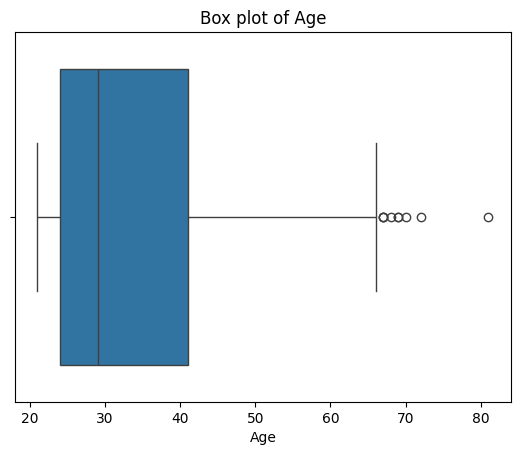

In [3]:
col = "Age"
print(df[col].describe()[["min", "25%", "50%", "75%", "max"]])     # the 5-number summary

sns.boxplot(x=df[col])
plt.title("Box plot of " + col)
plt.show()

**Correlate with the box plot:** left edge of the box = 25%, middle line = 50% (median), right edge = 75%, whiskers reach towards min and max, and dots beyond the whiskers are outliers.

### Q1.3 Bivariate analysis of two categorical variables (count plot)
Only Outcome is categorical, so make age groups as the second one.

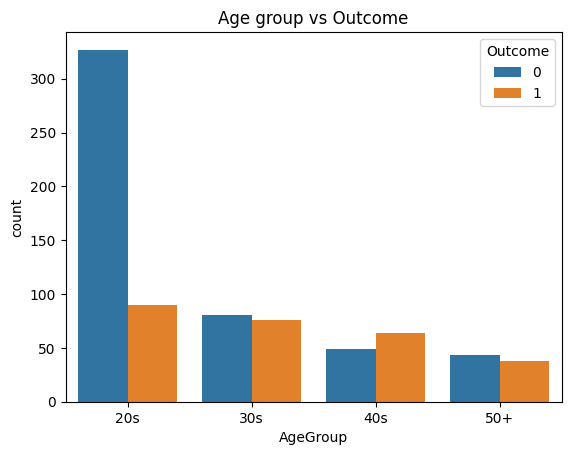

In [4]:
df["AgeGroup"] = pd.cut(df["Age"], bins=[20, 30, 40, 50, 90], labels=["20s", "30s", "40s", "50+"])
sns.countplot(x="AgeGroup", hue="Outcome", data=df)
plt.title("Age group vs Outcome")
plt.show()

### Q1.4 Binarise a numerical column with a threshold

In [5]:
from sklearn.preprocessing import Binarizer

df["HighGlucose"] = Binarizer(threshold=140).fit_transform(df[["Glucose"]]).ravel()   # > 140 -> 1, else 0
print(df[["Glucose", "HighGlucose"]].head())
print(df["HighGlucose"].value_counts())

   Glucose  HighGlucose
0      148            1
1       85            0
2      183            1
3       89            0
4      137            0
HighGlucose
0    576
1    192
Name: count, dtype: int64


### Q1.5 Remove highly correlated features

In [6]:
num = df.select_dtypes("number").drop(columns=["Outcome", "HighGlucose"])
corr = num.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))    # each pair once (upper triangle)
to_drop = [c for c in upper.columns if (upper[c] > 0.5).any()]
print("Highly correlated (> 0.5), dropping:", to_drop)
df = df.drop(columns=to_drop)

Highly correlated (> 0.5), dropping: ['Age']


Diabetes features are only weakly correlated, so 0.5 is used here. With strongly correlated data, use 0.8 or 0.9.

---
## Question 2

### Q2.1 Read and divide into training (70%) and testing (30%)
IRIS has 3 species. The question wants **2 categories**, so keep versicolor and virginica (the two that overlap).

In [7]:
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/IRIS.csv")
df = df[df["Species"] != "Iris-setosa"]
X = StandardScaler().fit_transform(df.drop(columns="Species"))
y = df["Species"]

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (70, 4)  Test: (30, 4)


### Q2.2–Q2.5 Build both models, evaluate, confusion tables, metrics

In [8]:
from sklearn.linear_model import Perceptron, LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

rows = []
for name, model in [("Perceptron", Perceptron(random_state=42)), ("Logistic Regression", LogisticRegression())]:
    pred = model.fit(X_train, y_train).predict(X_test)
    print(name, "confusion table:\n", confusion_matrix(y_test, pred))
    rows.append([name, accuracy_score(y_test, pred), precision_score(y_test, pred, average="macro"),
                 recall_score(y_test, pred, average="macro"), f1_score(y_test, pred, average="macro")])
results = pd.DataFrame(rows, columns=["Model", "Accuracy", "Precision", "Recall", "F-measure"]).set_index("Model")
results.round(4)

Perceptron confusion table:
 [[14  1]
 [ 2 13]]
Logistic Regression confusion table:
 [[14  1]
 [ 2 13]]


,Accuracy,Precision,Recall,F-measure
Model,,,,
Perceptron,0.9,0.9018,0.9,0.8999
Logistic Regression,0.9,0.9018,0.9,0.8999


### Q2.6 Plot the results and compare

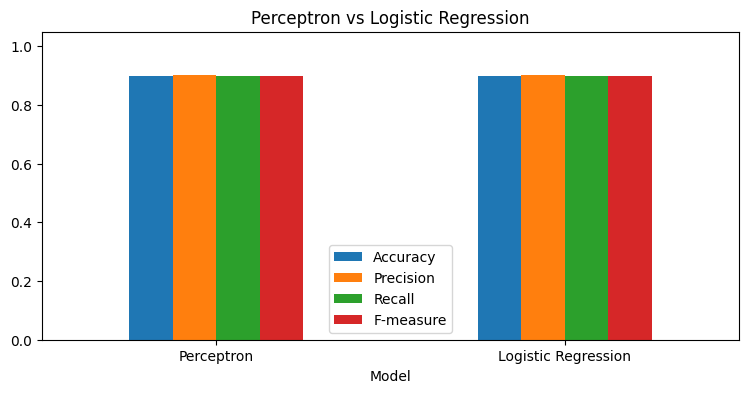

In [9]:
results.plot(kind="bar", rot=0, figsize=(9, 4))
plt.ylim(0, 1.05)
plt.title("Perceptron vs Logistic Regression")
plt.show()